# 04 — Classical System Identification

## Objective

This notebook estimates the physical parameters of the deterministic MEMS dynamical system directly from simulated input-output data.

For the linear baseline model,

$$
m\ddot{x} + c\dot{x} + kx = F(t),
$$

the unknown physical parameters are

$$
m,\qquad c,\qquad k.
$$

The governing equation can be written in regression form as

$$
F(t)
=
\begin{bmatrix}
\ddot{x}(t) & \dot{x}(t) & x(t)
\end{bmatrix}
\begin{bmatrix}
m\\
c\\
k
\end{bmatrix}.
$$

This makes it possible to estimate the physical parameters from the simulated time-series data using classical least-squares system identification.

The estimated parameters will then be compared with the known ground-truth values used to generate the deterministic simulation.

In [5]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


# Identify the project root directory.
PROJECT_ROOT = Path.cwd().parent


# Add the project root to Python's import path so that
# modules inside src/ can be imported from the notebook.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


# Standard scientific Python libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Project utility functions.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

In [6]:
# LOAD THE DETERMINISTIC BASELINE DATA


# Define the path to the raw deterministic simulation data.
baseline_data_path = (
    data_path("raw")
    / "deterministic_baseline.csv"
)


# Load the CSV file into a pandas DataFrame.
baseline_data = pd.read_csv(
    baseline_data_path
)


# Display the first rows so we can verify the available columns.
baseline_data.head()

,time,excitation,displacement,velocity,acceleration,measured_signal
0,0.0000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
1,0.0001,0.000629,1.047444e-12,3.142576e-08,0.000629,0.000629
2,0.0002,0.001258,8.381102e-12,1.257422e-07,0.001258,0.001258
3,0.0003,0.001888,2.829303e-11,2.830075e-07,0.001888,0.001888
4,0.0004,0.002518,6.708149e-11,5.032792e-07,0.002518,0.002518


In [7]:
# CONSTRUCT THE SYSTEM-IDENTIFICATION REGRESSION PROBLEM


# Extract the physical time-series variables from the dataset.
displacement = baseline_data[
    "displacement"
].to_numpy()

velocity = baseline_data[
    "velocity"
].to_numpy()

acceleration = baseline_data[
    "acceleration"
].to_numpy()

excitation = baseline_data[
    "excitation"
].to_numpy()


# Construct the regression matrix.
#
# Each row corresponds to:
#
# [acceleration, velocity, displacement]
#
# so that:
#
# F = m*a + c*v + k*x
#
regression_matrix = np.column_stack(
    (
        acceleration,
        velocity,
        displacement,
    )
)


# The excitation force is the target vector.
target_force = excitation


print(
    f"Regression matrix shape: "
    f"{regression_matrix.shape}"
)

print(
    f"Target vector shape:      "
    f"{target_force.shape}"
)

print()
print("First five rows of the regression matrix:")
print(regression_matrix[:5])

Regression matrix shape: (20001, 3)
Target vector shape:      (20001,)

First five rows of the regression matrix:
[[0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [6.28613379e-04 3.14257639e-08 1.04744362e-12]
 [1.25781209e-03 1.25742185e-07 8.38110181e-12]
 [1.88758960e-03 2.83007471e-07 2.82930311e-11]
 [2.51793934e-03 5.03279175e-07 6.70814856e-11]]


In [8]:
# ESTIMATE THE PHYSICAL PARAMETERS USING LEAST SQUARES


# Solve the overdetermined linear system:
#
#     X * theta ≈ F
#
# where:
#
#     theta = [mass, damping, stiffness]
#
# np.linalg.lstsq returns the parameter vector that minimizes
# the sum of squared differences between the measured target
# force and the force reconstructed by the model.

estimated_parameters, residuals, rank, singular_values = (
    np.linalg.lstsq(
        regression_matrix,
        target_force,
        rcond=None,
    )
)


# Extract the individual estimated physical parameters.
estimated_mass = estimated_parameters[0]
estimated_damping = estimated_parameters[1]
estimated_stiffness = estimated_parameters[2]


print(
    f"Estimated mass:      "
    f"{estimated_mass:.10f}"
)

print(
    f"Estimated damping:   "
    f"{estimated_damping:.10f}"
)

print(
    f"Estimated stiffness: "
    f"{estimated_stiffness:.10f}"
)

print()
print(
    f"Regression matrix rank: "
    f"{rank}"
)

print(
    "Singular values:"
)
print(singular_values)

print()
print(
    "Least-squares residual output:"
)
print(residuals)

Estimated mass:      1.0000000000
Estimated damping:   0.0800000000
Estimated stiffness: 1000.0000000000

Regression matrix rank: 3
Singular values:
[4.34906150e+02 1.34928137e+01 9.65067741e-02]

Least-squares residual output:
[2.7253495e-23]


## Least-Squares Parameter Identification

The deterministic baseline data were used to estimate the physical parameters of the linear dynamical system

$$
m\ddot{x}+c\dot{x}+kx=F(t).
$$

The least-squares estimates were

$$
\hat{m}=1.000000,
$$

$$
\hat{c}=0.080000,
$$

and

$$
\hat{k}=1000.000000.
$$

These values reproduce the ground-truth parameters used in the deterministic simulation.

The regression matrix had rank

$$
3,
$$

which corresponds to the number of unknown parameters and indicates that the available data contain sufficient independent information to identify all three parameters.

The least-squares residual was approximately

$$
2.73\times10^{-23},
$$

which is effectively zero at numerical precision. The governing equation can therefore reconstruct the excitation force almost exactly for the deterministic, noise-free baseline.

This result provides an ideal reference case. Later analyses can evaluate how parameter identification deteriorates when measurement noise, parameter uncertainty, nonlinear behaviour, or incomplete observations are introduced.

In [9]:
# COMPARE ESTIMATED PARAMETERS WITH GROUND TRUTH

# Ground-truth parameters used in the deterministic simulation.
true_mass = 1.0
true_damping = 0.08
true_stiffness = 1000.0


# Create a comparison table.
parameter_comparison = pd.DataFrame(
    {
        "parameter": [
            "mass",
            "damping",
            "stiffness",
        ],

        "true_value": [
            true_mass,
            true_damping,
            true_stiffness,
        ],

        "estimated_value": [
            estimated_mass,
            estimated_damping,
            estimated_stiffness,
        ],
    }
)


# Calculate absolute estimation error.
parameter_comparison["absolute_error"] = np.abs(
    parameter_comparison["estimated_value"]
    - parameter_comparison["true_value"]
)


# Calculate relative error as a percentage.
parameter_comparison["relative_error_percent"] = (
    parameter_comparison["absolute_error"]
    / np.abs(parameter_comparison["true_value"])
    * 100.0
)


parameter_comparison

,parameter,true_value,estimated_value,absolute_error,relative_error_percent
0,mass,1.00,1.00,6.883383e-15,6.883383e-13
1,damping,0.08,0.08,2.682993e-13,3.353741e-10
2,stiffness,1000.00,1000.00,2.034994e-11,2.034994e-12


In [10]:
# RECONSTRUCT THE EXCITATION USING THE IDENTIFIED MODEL

# Use the estimated parameters and the measured state variables
# to reconstruct the force predicted by the identified model.
#
# F_hat(t) = m_hat * a(t)
#          + c_hat * v(t)
#          + k_hat * x(t)

reconstructed_force = (
    estimated_mass * acceleration
    + estimated_damping * velocity
    + estimated_stiffness * displacement
)


# Calculate the reconstruction error at every time sample.
force_reconstruction_error = (
    target_force
    - reconstructed_force
)


# Calculate useful error metrics.
force_rmse = np.sqrt(
    np.mean(
        force_reconstruction_error ** 2
    )
)

force_mae = np.mean(
    np.abs(
        force_reconstruction_error
    )
)

force_max_absolute_error = np.max(
    np.abs(
        force_reconstruction_error
    )
)


print(
    f"Force reconstruction RMSE:      "
    f"{force_rmse:.12e}"
)

print(
    f"Force reconstruction MAE:       "
    f"{force_mae:.12e}"
)

print(
    f"Maximum absolute force error:   "
    f"{force_max_absolute_error:.12e}"
)

Force reconstruction RMSE:      4.463914844791e-14
Force reconstruction MAE:       3.558620840839e-14
Maximum absolute force error:   1.487976408754e-13


### Force Reconstruction Accuracy

The excitation force reconstructed from the identified parameters was compared with the original excitation signal.

The reconstruction errors were extremely small:

$$
\mathrm{RMSE} \approx 4.46\times10^{-14},
$$

$$
\mathrm{MAE} \approx 3.56\times10^{-14},
$$

and the maximum absolute error was approximately

$$
1.49\times10^{-13}.
$$

These values are effectively zero at numerical precision and confirm that the identified parameters reproduce the deterministic governing equation accurately.

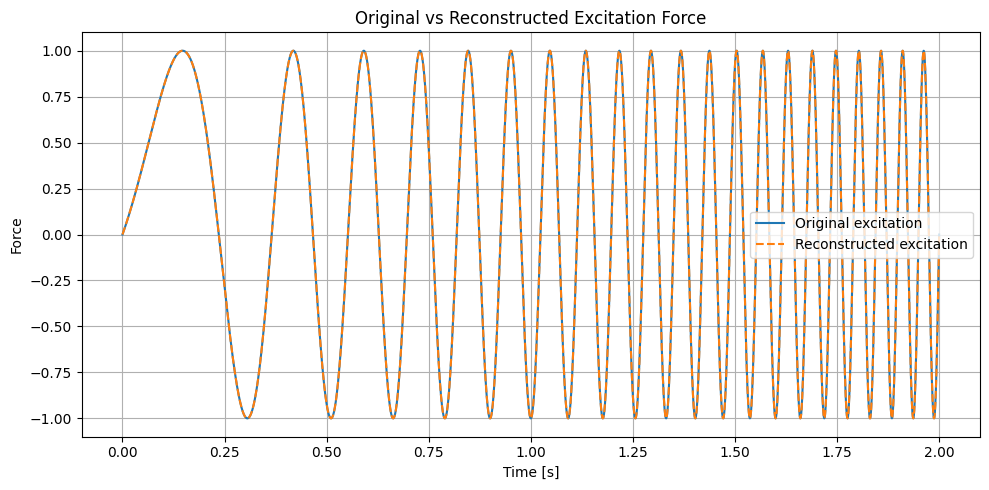

In [11]:
# PLOT ORIGINAL AND RECONSTRUCTED EXCITATION


time_values = baseline_data[
    "time"
].to_numpy()


plt.figure(figsize=(10, 5))

plt.plot(
    time_values,
    target_force,
    label="Original excitation",
)

plt.plot(
    time_values,
    reconstructed_force,
    linestyle="--",
    label="Reconstructed excitation",
)


plt.xlabel("Time [s]")
plt.ylabel("Force")
plt.title(
    "Original vs Reconstructed Excitation Force"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [12]:
# EVALUATE THE CONDITIONING OF THE REGRESSION MATRIX

# The condition number is the ratio between the largest
# and smallest singular values.
#
# A larger condition number means that the parameter estimates
# may become more sensitive to noise or small perturbations
# in the data.

condition_number = (
    singular_values[0]
    / singular_values[-1]
)


print(
    f"Regression matrix condition number: "
    f"{condition_number:.6f}"
)

Regression matrix condition number: 4506.483142


### Conditioning of the Identification Problem

The raw regression matrix had a condition number of approximately

$$
\kappa(\mathbf{X}) = 4506.48.
$$

A large condition number can indicate increased sensitivity of parameter estimates to perturbations in the data. However, the regression variables in the present physical model have different units and substantially different numerical scales.

Therefore, the raw condition number alone should not be interpreted as evidence of severe parameter non-identifiability. To separate the effect of numerical scaling from genuine dependence between the regression variables, the condition number is also evaluated after column normalization.

In [13]:
# EVALUATE CONDITIONING AFTER COLUMN NORMALIZATION

# Calculate the Euclidean norm of each column in the
# regression matrix.
#
# The three columns correspond to:
#
# acceleration, velocity, displacement.
column_norms = np.linalg.norm(
    regression_matrix,
    axis=0,
)


# Normalize every column by its own magnitude.
#
# This removes differences caused purely by numerical scale
# while preserving the time-dependent shape of each variable.
normalized_regression_matrix = (
    regression_matrix
    / column_norms
)


# Calculate the singular values of the normalized matrix.
normalized_singular_values = np.linalg.svd(
    normalized_regression_matrix,
    compute_uv=False,
)


# Calculate the condition number after normalization.
normalized_condition_number = (
    normalized_singular_values[0]
    / normalized_singular_values[-1]
)


print("Column norms:")
print(column_norms)

print()

print("Normalized singular values:")
print(normalized_singular_values)

print()

print(
    f"Raw condition number:        "
    f"{condition_number:.6f}"
)

print(
    f"Normalized condition number: "
    f"{normalized_condition_number:.6f}"
)

Column norms:
[4.34905927e+02 1.34937129e+01 4.23338453e-01]

Normalized singular values:
[1.40483116 1.00006183 0.16225212]

Raw condition number:        4506.483142
Normalized condition number: 8.658322


After normalizing the three regression columns by their Euclidean norms, the condition number decreased from

$$
4506.48
$$

to approximately

$$
8.66.
$$

This substantial reduction shows that the large raw condition number was primarily caused by the different numerical scales of acceleration, velocity, and displacement rather than by severe linear dependence between the regressors.

The normalized identification problem is therefore reasonably well conditioned for the deterministic baseline. Nevertheless, conditioning remains important because measurement noise and modelling errors can still affect parameter estimates in more realistic cases.

In [14]:
# CREATE A NOISY ACCELERATION MEASUREMENT

# Use a fixed random seed so that the experiment is
# reproducible every time the notebook is executed.
random_generator = np.random.default_rng(
    seed=9512
)


# Choose a moderate measurement-noise standard deviation.
#
# This is an experimental value used to study the sensitivity
# of classical system identification to sensor noise.
noise_standard_deviation = 0.05


# Generate zero-mean Gaussian measurement noise.
acceleration_noise = random_generator.normal(
    loc=0.0,
    scale=noise_standard_deviation,
    size=acceleration.shape,
)


# Add the noise to the true acceleration.
noisy_acceleration = (
    acceleration
    + acceleration_noise
)


# Calculate the actual noise statistics produced by this
# particular random realization.
realized_noise_mean = np.mean(
    acceleration_noise
)

realized_noise_std = np.std(
    acceleration_noise
)


print(
    f"Specified noise standard deviation: "
    f"{noise_standard_deviation:.6f}"
)

print(
    f"Realized noise mean:               "
    f"{realized_noise_mean:.6f}"
)

print(
    f"Realized noise standard deviation: "
    f"{realized_noise_std:.6f}"
)

Specified noise standard deviation: 0.050000
Realized noise mean:               -0.000067
Realized noise standard deviation: 0.049848


In [15]:
# IDENTIFY PARAMETERS USING THE NOISY ACCELERATION SIGNAL

# Construct a new regression matrix.
#
# The displacement and velocity remain ideal in this controlled
# experiment, while acceleration now contains measurement noise.
noisy_regression_matrix = np.column_stack(
    (
        noisy_acceleration,
        velocity,
        displacement,
    )
)


# Estimate the parameters again using least squares.
noisy_estimated_parameters, noisy_residuals, noisy_rank, noisy_singular_values = (
    np.linalg.lstsq(
        noisy_regression_matrix,
        target_force,
        rcond=None,
    )
)


# Extract the estimated physical parameters.
noisy_estimated_mass = noisy_estimated_parameters[0]
noisy_estimated_damping = noisy_estimated_parameters[1]
noisy_estimated_stiffness = noisy_estimated_parameters[2]


print(
    f"Estimated mass with noise:      "
    f"{noisy_estimated_mass:.10f}"
)

print(
    f"Estimated damping with noise:   "
    f"{noisy_estimated_damping:.10f}"
)

print(
    f"Estimated stiffness with noise: "
    f"{noisy_estimated_stiffness:.10f}"
)

print()

print(
    f"Noisy regression matrix rank: "
    f"{noisy_rank}"
)

print()

print(
    "Least-squares residual output:"
)

print(
    noisy_residuals
)

Estimated mass with noise:      0.9954211531
Estimated damping with noise:   0.0841385984
Estimated stiffness with noise: 995.5990751505

Noisy regression matrix rank: 3

Least-squares residual output:
[49.48510324]


## System Identification with Measurement Noise

To investigate the sensitivity of classical system identification to measurement uncertainty, Gaussian noise with a standard deviation of

$$
\sigma = 0.05
$$

was added to the acceleration signal while displacement and velocity were kept noise-free.

Using the noisy acceleration measurements, the estimated parameters became

$$
\hat{m}=0.995421,
$$

$$
\hat{c}=0.084139,
$$

and

$$
\hat{k}=995.599075.
$$

The regression matrix remained full rank, indicating that all three parameters were still identifiable from the available data.

However, unlike the deterministic case, the estimates no longer reproduced the exact ground-truth parameters. The least-squares residual increased to approximately

$$
49.49.
$$

This demonstrates that measurement noise in a regression variable can influence the identified physical parameters. In this experiment, the acceleration itself is uncertain, creating an errors-in-variables problem rather than the ideal classical regression case.

In [16]:
# QUANTIFY PARAMETER ERRORS UNDER MEASUREMENT NOISE


# Create a comparison table between the true parameters
# and the estimates obtained from noisy acceleration data.

noisy_parameter_comparison = pd.DataFrame(
    {
        "parameter": [
            "mass",
            "damping",
            "stiffness",
        ],

        "true_value": [
            true_mass,
            true_damping,
            true_stiffness,
        ],

        "estimated_value": [
            noisy_estimated_mass,
            noisy_estimated_damping,
            noisy_estimated_stiffness,
        ],
    }
)


# Calculate the absolute estimation error.
noisy_parameter_comparison["absolute_error"] = np.abs(
    noisy_parameter_comparison["estimated_value"]
    - noisy_parameter_comparison["true_value"]
)


# Calculate the relative estimation error in percent.
noisy_parameter_comparison["relative_error_percent"] = (
    noisy_parameter_comparison["absolute_error"]
    / np.abs(noisy_parameter_comparison["true_value"])
    * 100.0
)


noisy_parameter_comparison

,parameter,true_value,estimated_value,absolute_error,relative_error_percent
0,mass,1.00,0.995421,0.004579,0.457885
1,damping,0.08,0.084139,0.004139,5.173248
2,stiffness,1000.00,995.599075,4.400925,0.440092


### Parameter Sensitivity to Acceleration Noise

The relative parameter errors obtained after adding acceleration measurement noise were approximately

$$
0.458\%
$$

for mass,

$$
5.173\%
$$

for damping, and

$$
0.440\%
$$

for stiffness.

Mass and stiffness therefore remained close to their ground-truth values, whereas the damping estimate showed a noticeably larger relative deviation.

This indicates that the damping coefficient is more sensitive to the present acceleration perturbation in this particular experiment. Since the damping contribution to the governing equation is comparatively small, noise in the measured dynamics can produce a larger relative change in its estimated coefficient.

However, this result is based on one noise realization. A later Monte Carlo analysis is required to determine whether this sensitivity persists statistically across repeated uncertain measurements.

In [17]:
# RECONSTRUCT THE FORCE USING THE NOISY IDENTIFIED MODEL


# Reconstruct the excitation using:
#
# - the parameters estimated from noisy data,
# - the noisy acceleration measurement,
# - the ideal velocity and displacement signals.
#
# F_hat_noisy(t)
#     = m_hat * a_noisy(t)
#     + c_hat * v(t)
#     + k_hat * x(t)

noisy_reconstructed_force = (
    noisy_estimated_mass * noisy_acceleration
    + noisy_estimated_damping * velocity
    + noisy_estimated_stiffness * displacement
)


# Calculate the difference between the original excitation
# and the force reconstructed by the noisy identified model.
noisy_force_error = (
    target_force
    - noisy_reconstructed_force
)


# Calculate reconstruction error metrics.
noisy_force_rmse = np.sqrt(
    np.mean(
        noisy_force_error ** 2
    )
)

noisy_force_mae = np.mean(
    np.abs(
        noisy_force_error
    )
)

noisy_force_max_absolute_error = np.max(
    np.abs(
        noisy_force_error
    )
)


print(
    f"Noisy force reconstruction RMSE:    "
    f"{noisy_force_rmse:.6f}"
)

print(
    f"Noisy force reconstruction MAE:     "
    f"{noisy_force_mae:.6f}"
)

print(
    f"Maximum absolute force error:        "
    f"{noisy_force_max_absolute_error:.6f}"
)

Noisy force reconstruction RMSE:    0.049741
Noisy force reconstruction MAE:     0.039731
Maximum absolute force error:        0.199047


### Force Reconstruction with Noisy Measurements

Using the parameters identified from the noisy acceleration measurements, the reconstructed excitation produced

$$
\mathrm{RMSE}=0.049741,
$$

$$
\mathrm{MAE}=0.039731,
$$

and a maximum absolute error of

$$
0.199047.
$$

The reconstruction RMSE is approximately equal to the imposed acceleration-noise standard deviation of

$$
\sigma=0.05.
$$

This indicates that the remaining force-reconstruction error is largely associated with the introduced measurement noise.

Although the estimated physical parameters are no longer exact, the identified model still reproduces the excitation reasonably well. This illustrates an important distinction between parameter-estimation accuracy and overall signal-reconstruction accuracy.

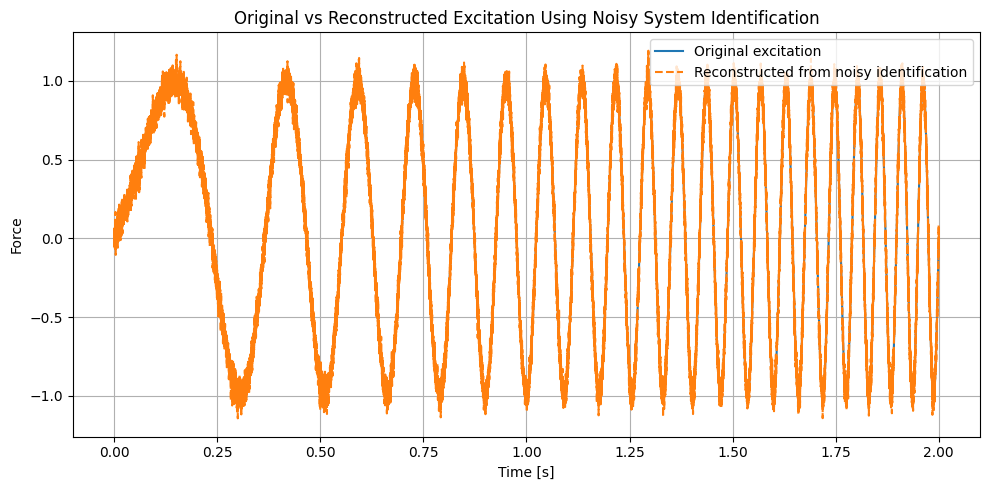

In [18]:
# PLOT ORIGINAL AND NOISY-MODEL RECONSTRUCTED FORCE


plt.figure(figsize=(10, 5))

plt.plot(
    time_values,
    target_force,
    label="Original excitation",
)

plt.plot(
    time_values,
    noisy_reconstructed_force,
    linestyle="--",
    label="Reconstructed from noisy identification",
)


plt.xlabel("Time [s]")
plt.ylabel("Force")

plt.title(
    "Original vs Reconstructed Excitation "
    "Using Noisy System Identification"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

Residual mean:               0.000261
Residual standard deviation: 0.049740


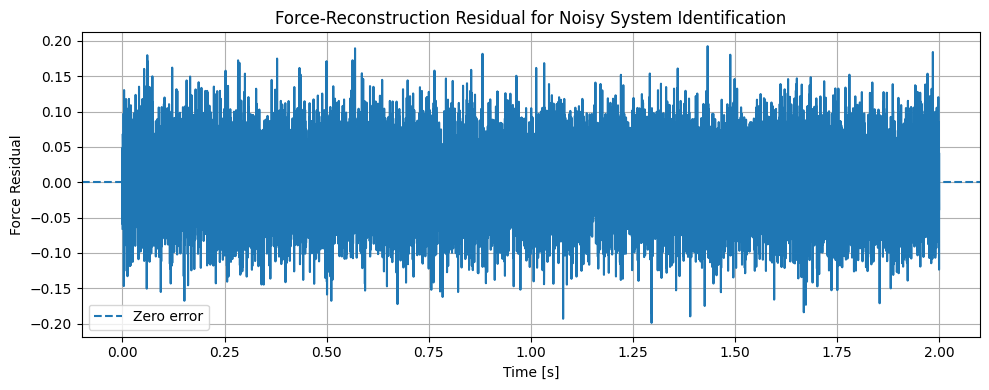

In [19]:
# ANALYSE THE FORCE-RECONSTRUCTION RESIDUAL


# The residual is the difference between the true excitation
# and the force predicted by the noisy identified model.
#
# e(t) = F(t) - F_hat(t)

residual_mean = np.mean(
    noisy_force_error
)

residual_standard_deviation = np.std(
    noisy_force_error
)


print(
    f"Residual mean:               "
    f"{residual_mean:.6f}"
)

print(
    f"Residual standard deviation: "
    f"{residual_standard_deviation:.6f}"
)


# Plot the residual over time.
plt.figure(figsize=(10, 4))

plt.plot(
    time_values,
    noisy_force_error,
)

plt.axhline(
    0.0,
    linestyle="--",
    label="Zero error",
)

plt.xlabel("Time [s]")
plt.ylabel("Force Residual")

plt.title(
    "Force-Reconstruction Residual "
    "for Noisy System Identification"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

### Residual Analysis

The force-reconstruction residual had a mean of approximately

$$
0.000261,
$$

which is very close to zero.

Its standard deviation was

$$
0.049740,
$$

which is nearly equal to the imposed acceleration-noise standard deviation of

$$
0.05.
$$

The residual also fluctuates around zero without an obvious systematic trend.

These results support the interpretation that the remaining reconstruction error is predominantly noise-like rather than being caused by a strong deterministic mismatch in the identified physical model.

In [21]:
# STUDY PARAMETER SENSITIVITY ACROSS MULTIPLE NOISE LEVELS

# Define several acceleration-noise standard deviations.
noise_levels = [
    0.00,
    0.01,
    0.02,
    0.05,
    0.10,
]


# Use one reproducible random-number generator.
noise_study_rng = np.random.default_rng(
    seed=9512
)


# Store the results from each noise level.
noise_sensitivity_results = []


for noise_level in noise_levels:

    # Generate acceleration noise.
    acceleration_noise_current = (
        noise_study_rng.normal(
            loc=0.0,
            scale=noise_level,
            size=acceleration.shape,
        )
    )


    # Create noisy acceleration measurements.
    noisy_acceleration_current = (
        acceleration
        + acceleration_noise_current
    )


    # Construct the regression matrix.
    regression_matrix_current = np.column_stack(
        (
            noisy_acceleration_current,
            velocity,
            displacement,
        )
    )


    # Estimate the physical parameters.
    estimated_parameters_current = np.linalg.lstsq(
        regression_matrix_current,
        target_force,
        rcond=None,
    )[0]


    mass_current = estimated_parameters_current[0]
    damping_current = estimated_parameters_current[1]
    stiffness_current = estimated_parameters_current[2]


    # Calculate relative parameter errors.
    mass_error_percent = (
        abs(mass_current - true_mass)
        / true_mass
        * 100.0
    )

    damping_error_percent = (
        abs(damping_current - true_damping)
        / true_damping
        * 100.0
    )

    stiffness_error_percent = (
        abs(stiffness_current - true_stiffness)
        / true_stiffness
        * 100.0
    )


    # Save the results for this noise level.
    noise_sensitivity_results.append(
        {
            "noise_standard_deviation": noise_level,
            "estimated_mass": mass_current,
            "estimated_damping": damping_current,
            "estimated_stiffness": stiffness_current,
            "mass_error_percent": mass_error_percent,
            "damping_error_percent": damping_error_percent,
            "stiffness_error_percent": stiffness_error_percent,
        }
    )


# Convert the results into a DataFrame.
noise_sensitivity_table = pd.DataFrame(
    noise_sensitivity_results
)


noise_sensitivity_table

,noise_standard_deviation,estimated_mass,estimated_damping,estimated_stiffness,mass_error_percent,damping_error_percent,stiffness_error_percent
0,0.00,1.000000,0.080000,1000.000000,6.883383e-13,3.353741e-10,2.034994e-12
1,0.01,0.999833,0.079336,999.801900,1.674184e-02,8.297015e-01,1.980997e-02
2,0.02,0.999368,0.078866,999.399674,6.319513e-02,1.417474e+00,6.003265e-02
3,0.05,0.994162,0.082879,994.187842,5.838358e-01,3.599284e+00,5.812158e-01
4,0.10,0.980876,0.092525,980.966666,1.912422e+00,1.565602e+01,1.903333e+00


### Sensitivity to Measurement-Noise Level

The parameter-identification experiment was repeated for several acceleration-noise levels.

As the measurement-noise standard deviation increased, the estimation errors generally increased.

Mass and stiffness showed relatively gradual deterioration. At a noise standard deviation of

$$
\sigma = 0.10,
$$

their relative errors were approximately

$$
1.91\%
$$

and

$$
1.90\%,
$$

respectively.

The damping coefficient was substantially more sensitive. Its relative error increased from approximately

$$
0.83\%
$$

at

$$
\sigma = 0.01
$$

to approximately

$$
15.66\%
$$

at

$$
\sigma = 0.10.
$$

This sensitivity sweep indicates that the damping parameter is particularly vulnerable to acceleration-measurement noise in the present identification formulation.

Each noise level in this experiment is represented by one random realization. Therefore, the observed trend should be interpreted as a sensitivity study rather than a complete statistical uncertainty analysis. Repeated Monte Carlo identification will later be required to quantify the variability of the parameter estimates.

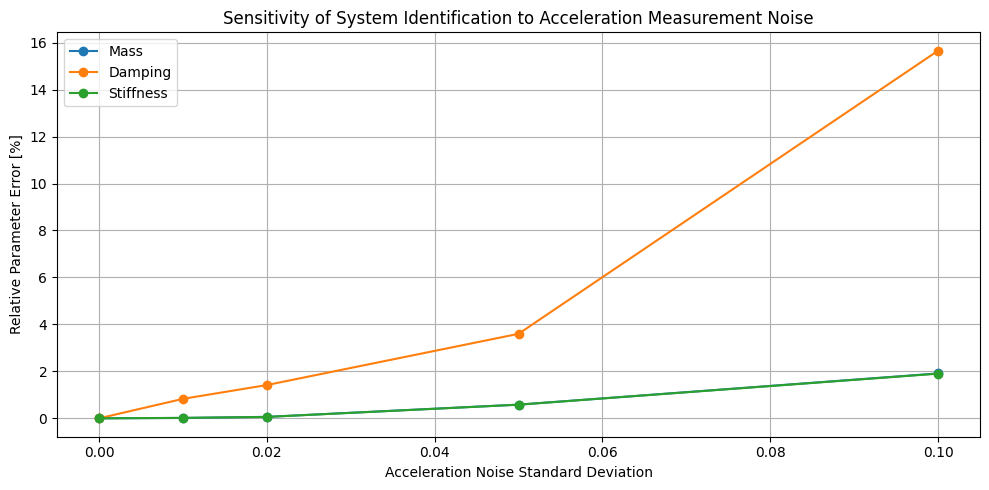

In [22]:
# PLOT PARAMETER-ESTIMATION ERROR VS NOISE LEVEL

plt.figure(figsize=(10, 5))

plt.plot(
    noise_sensitivity_table["noise_standard_deviation"],
    noise_sensitivity_table["mass_error_percent"],
    marker="o",
    label="Mass",
)

plt.plot(
    noise_sensitivity_table["noise_standard_deviation"],
    noise_sensitivity_table["damping_error_percent"],
    marker="o",
    label="Damping",
)

plt.plot(
    noise_sensitivity_table["noise_standard_deviation"],
    noise_sensitivity_table["stiffness_error_percent"],
    marker="o",
    label="Stiffness",
)


plt.xlabel(
    "Acceleration Noise Standard Deviation"
)

plt.ylabel(
    "Relative Parameter Error [%]"
)

plt.title(
    "Sensitivity of System Identification "
    "to Acceleration Measurement Noise"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

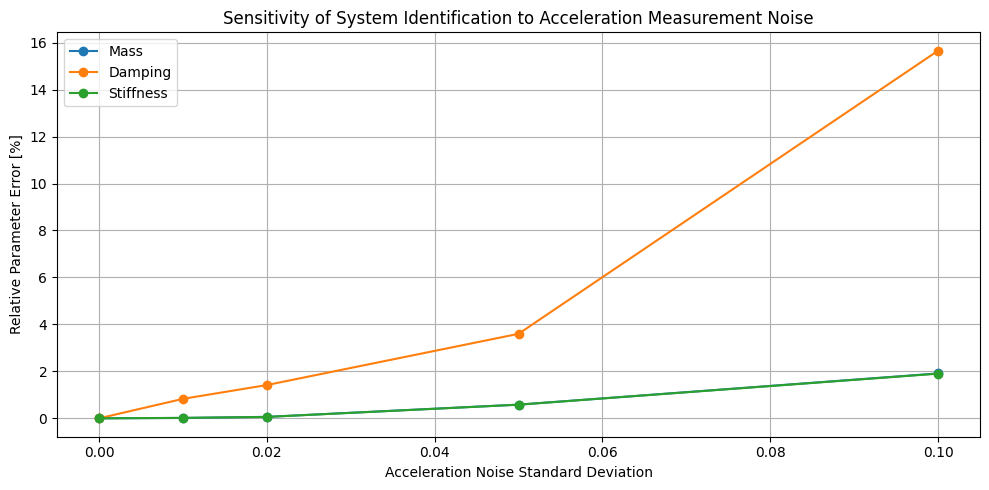

Noise-sensitivity table saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\system_identification\noise_sensitivity_parameter_errors.csv

Noise-sensitivity figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\system_identification\noise_sensitivity_parameter_errors.png


In [23]:
# SAVE THE NOISE-SENSITIVITY RESULTS


# Create the system-identification results directory.
system_identification_results_directory = results_path(
    "system_identification"
)

ensure_directory(
    system_identification_results_directory
)


# Create the corresponding figure directory.
system_identification_figure_directory = figures_path(
    "system_identification"
)

ensure_directory(
    system_identification_figure_directory
)



# SAVE THE NUMERICAL SENSITIVITY TABLE

noise_sensitivity_results_path = (
    system_identification_results_directory
    / "noise_sensitivity_parameter_errors.csv"
)

noise_sensitivity_table.to_csv(
    noise_sensitivity_results_path,
    index=False,
)



# RECREATE AND SAVE THE SENSITIVITY FIGURE

plt.figure(figsize=(10, 5))

plt.plot(
    noise_sensitivity_table["noise_standard_deviation"],
    noise_sensitivity_table["mass_error_percent"],
    marker="o",
    label="Mass",
)

plt.plot(
    noise_sensitivity_table["noise_standard_deviation"],
    noise_sensitivity_table["damping_error_percent"],
    marker="o",
    label="Damping",
)

plt.plot(
    noise_sensitivity_table["noise_standard_deviation"],
    noise_sensitivity_table["stiffness_error_percent"],
    marker="o",
    label="Stiffness",
)

plt.xlabel(
    "Acceleration Noise Standard Deviation"
)

plt.ylabel(
    "Relative Parameter Error [%]"
)

plt.title(
    "Sensitivity of System Identification "
    "to Acceleration Measurement Noise"
)

plt.legend()
plt.grid(True)
plt.tight_layout()


noise_sensitivity_figure_path = (
    system_identification_figure_directory
    / "noise_sensitivity_parameter_errors.png"
)

plt.savefig(
    noise_sensitivity_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("Noise-sensitivity table saved to:")
print(noise_sensitivity_results_path)

print()

print("Noise-sensitivity figure saved to:")
print(noise_sensitivity_figure_path)

In [24]:
# SAVE PARAMETER-COMPARISON RESULTS

# Define output paths for the ideal and noisy
# parameter-identification results.
ideal_parameter_comparison_path = (
    system_identification_results_directory
    / "ideal_parameter_identification.csv"
)

noisy_parameter_comparison_path = (
    system_identification_results_directory
    / "noisy_parameter_identification.csv"
)


# Save the tables.
parameter_comparison.to_csv(
    ideal_parameter_comparison_path,
    index=False,
)

noisy_parameter_comparison.to_csv(
    noisy_parameter_comparison_path,
    index=False,
)


print("Ideal parameter comparison saved to:")
print(ideal_parameter_comparison_path)

print()

print("Noisy parameter comparison saved to:")
print(noisy_parameter_comparison_path)

Ideal parameter comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\system_identification\ideal_parameter_identification.csv

Noisy parameter comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\system_identification\noisy_parameter_identification.csv


In [26]:
# VERIFY THE REUSABLE IDENTIFICATION FUNCTION


module_estimated_parameters, _, _, _ = (
    estimate_linear_parameters(
        acceleration=acceleration,
        velocity=velocity,
        displacement=displacement,
        excitation=target_force,
    )
)


print(
    f"Mass from reusable function:      "
    f"{module_estimated_parameters[0]:.10f}"
)

print(
    f"Damping from reusable function:   "
    f"{module_estimated_parameters[1]:.10f}"
)

print(
    f"Stiffness from reusable function: "
    f"{module_estimated_parameters[2]:.10f}"
)

Mass from reusable function:      1.0000000000
Damping from reusable function:   0.0800000000
Stiffness from reusable function: 1000.0000000000


In [27]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 04


notebook_04_outputs = {
    "ideal_parameter_results": ideal_parameter_comparison_path,
    "noisy_parameter_results": noisy_parameter_comparison_path,
    "noise_sensitivity_results": noise_sensitivity_results_path,
    "noise_sensitivity_figure": noise_sensitivity_figure_path,
}


for output_name, output_path in notebook_04_outputs.items():

    print(
        f"{output_name:28s} "
        f"{output_path.exists()}"
    )

ideal_parameter_results      True
noisy_parameter_results      True
noise_sensitivity_results    True
noise_sensitivity_figure     True


# Notebook 04 Summary

This notebook applied classical least-squares system identification to the MEMS dynamical system

$$
m\ddot{x}+c\dot{x}+kx=F(t).
$$

For the deterministic noise-free baseline, the physical parameters were recovered as

$$
\hat{m}=1.000000,
$$

$$
\hat{c}=0.080000,
$$

and

$$
\hat{k}=1000.000000,
$$

matching the known ground-truth parameters to numerical precision.

The reconstructed excitation also agreed almost exactly with the original force signal, with a reconstruction RMSE on the order of

$$
10^{-14}.
$$

The raw regression matrix had a relatively large condition number of approximately

$$
4506.48.
$$

After normalizing the regression columns, the condition number decreased to approximately

$$
8.66,
$$

showing that much of the raw conditioning was caused by the different numerical scales of acceleration, velocity, and displacement rather than severe parameter non-identifiability.

Measurement noise was then introduced into the acceleration signal. For a noise standard deviation of

$$
\sigma=0.05,
$$

the identified parameters became approximately

$$
\hat{m}=0.9954,
\qquad
\hat{c}=0.0841,
\qquad
\hat{k}=995.60.
$$

The corresponding relative errors were approximately

$$
0.46\%
$$

for mass,

$$
5.17\%
$$

for damping, and

$$
0.44\%
$$

for stiffness.

Residual analysis showed a mean close to zero and a standard deviation close to the imposed measurement-noise level, indicating that the remaining reconstruction error was predominantly noise-like.

A sensitivity sweep over several acceleration-noise levels showed that parameter-estimation error increased with measurement uncertainty. Mass and stiffness remained comparatively robust, while damping was considerably more sensitive and reached an error of approximately

$$
15.66\%
$$

at a noise standard deviation of

$$
0.10.
$$

These results establish classical least-squares identification as a strong deterministic baseline while also demonstrating its sensitivity to noisy regression variables. This provides a reference for the subsequent equation-discovery, machine-learning, probabilistic, and uncertainty-aware methods.